# beta-VAE: Learning Basic Visual Concepts with a Constrained Variational Framework — Figure 7A–B

In [1]:
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
import hashlib, json, random, platform, inspect, linecache, time
from pathlib import Path
from urllib.request import urlopen
import shutil
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(items, **kwargs):
        return items

SEED, BATCH_SIZE, EPOCHS = 42, 256, 100
BETAS, LATENT_DIM, LR = (4.0, 1.0), 10, 0.01
OUT = Path("results"); OUT.mkdir(exist_ok=True)
DATA = Path(os.environ.get("ASSIGNMENT2_DATA", "data")) / "dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz"
DATA_URL = ("https://raw.githubusercontent.com/google-deepmind/dsprites-dataset/"
            "master/" + DATA.name)  # Dataset archive only; no model code.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.use_deterministic_algorithms(True)
torch.backends.cudnn.benchmark = False
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

def seed_all():
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

seed_all()
print(f"Device: {DEVICE}; {EPOCHS} epochs per model; seed {SEED}")

In [2]:
if not DATA.exists():
    DATA.parent.mkdir(parents=True, exist_ok=True)
    temporary = DATA.with_suffix(".download")
    with urlopen(DATA_URL, timeout=120) as response, open(temporary, "wb") as f:
        shutil.copyfileobj(response, f)
    temporary.replace(DATA)

def load_data():
    with np.load(DATA, allow_pickle=False) as archive:
        images = archive["imgs"]
        classes = archive["latents_classes"].astype(np.int64)
        values = archive["latents_values"]

    FACTOR_SIZES = (1, 3, 6, 40, 32, 32)  # color, shape, scale, rotation, X, Y
    N = int(np.prod(FACTOR_SIZES))
    assert images.shape == (N, 64, 64) and classes.shape == values.shape == (N, 6)
    assert images.dtype in (np.dtype("uint8"), np.dtype("bool"))
    assert images.min() == 0 and images.max() == 1
    for column, size in enumerate(FACTOR_SIZES):
        assert np.array_equal(np.unique(classes[:, column]), np.arange(size))
    factor_codes = np.ravel_multi_index(classes.T, FACTOR_SIZES)
    assert np.array_equal(np.sort(factor_codes), np.arange(N))
    assert np.isfinite(values).all()
    train_data = TensorDataset(torch.from_numpy(images))  # NO factor labels
    DATA_HASH = sha256(DATA)
    return images, classes, values, N, train_data, DATA_HASH

images, classes, values, N, train_data, DATA_HASH = load_data()
print(f"{N:,} binary images; {N // BATCH_SIZE:,} updates/epoch; SHA256 {DATA_HASH}")

In [3]:
class VAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(4096, 1200), nn.ReLU(),
                                     nn.Linear(1200, 1200), nn.ReLU())
        self.mean = nn.Linear(1200, LATENT_DIM)
        self.logvar = nn.Linear(1200, LATENT_DIM)
        self.decoder = nn.Sequential(
            nn.Linear(LATENT_DIM, 1200), nn.Tanh(),
            nn.Linear(1200, 1200), nn.Tanh(),
            nn.Linear(1200, 1200), nn.Tanh(), nn.Linear(1200, 4096))
        for layer in self.modules():
            if isinstance(layer, nn.Linear):
                nn.init.xavier_uniform_(layer.weight, gain=1.0)
                nn.init.zeros_(layer.bias)

    def encode(self, x):
        h = self.encoder(x.flatten(1))
        return self.mean(h), self.logvar(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
        return self.decoder(z), mu, logvar

def loss_terms(logits, x, mu, logvar):
    reconstruction = F.binary_cross_entropy_with_logits(
        logits, x.flatten(1), reduction="none").sum(dim=1)
    kl = 0.5 * (mu.square() + logvar.exp() - 1 - logvar).sum(dim=1)
    return reconstruction, kl

# Analytic reduction checks, independent of training outcomes.
x0, mu0 = torch.zeros(2, 4096), torch.zeros(2, LATENT_DIM)
r0, k0 = loss_terms(x0, x0, mu0, mu0)
assert torch.allclose(r0, torch.full_like(r0, 4096 * np.log(2)))
assert torch.equal(k0, torch.zeros_like(k0))
_, k1 = loss_terms(x0, x0, torch.ones_like(mu0), mu0)
assert torch.allclose(k1, torch.full_like(k1, LATENT_DIM / 2))
assert torch.allclose((r0 + 4*k1) - (r0 + k1), 3*k1)
print("Loss reductions and beta weighting passed.")

In [4]:
RUN_SPEC = dict(seed=SEED, batch_size=BATCH_SIZE, lr=LR, latent_dim=LATENT_DIM,
                architecture="FC:4096-1200-1200;Gaussian10;10-1200-1200-1200-4096",
                activations="encoder:ReLU;decoder-hidden:tanh;output:linear-logits",
                init="Xavier_uniform_gain1_bias0", optimizer="Adagrad",
                eps=1e-10, initial_accumulator_value=0.1, lr_decay=0.0,
                weight_decay=0.0, loss="pixel_sum+beta*latent_sum;batch_mean",
                data_sha256=DATA_HASH, torch=str(torch.__version__),
                numpy=str(np.__version__), python=platform.python_version(),
                device=str(DEVICE), deterministic=True)

def checkpoint_path(beta):
    return OUT / f"beta_{beta:g}_seed{SEED}.pt"

def training_code_sha256():
    # Hash executed source, independent of notebook paths, outputs and cell counters.
    functions = [seed_all, sha256, load_data, loss_terms, train]
    functions += [method for method in vars(VAE).values() if inspect.isfunction(method)]
    sources = {}
    for function in functions:
        lines = linecache.getlines(function.__code__.co_filename)
        if not lines:
            raise RuntimeError("Training source unavailable: run the notebook in Jupyter "
                               "with source caching; checkpoint compatibility cannot be verified.")
        sources[function.__qualname__] = "".join(lines).replace("\r\n", "\n")
    encoded = json.dumps(sources, sort_keys=True, ensure_ascii=False).encode("utf-8")
    return hashlib.sha256(encoded).hexdigest()

def validate_checkpoint(saved, beta, code_hash):
    recorded = saved.get("training_code_sha256")
    if recorded is None:
        raise RuntimeError("Checkpoint has no training-code hash; resume refused. "
                           "Keep it unchanged and use a new output directory for a fresh run.")
    if recorded != code_hash:
        raise RuntimeError(f"Training-code hash mismatch: checkpoint={recorded}, current={code_hash}. "
                           "Resume refused; use the original code or a new output directory.")
    if saved.get("spec") != dict(RUN_SPEC, beta=beta):
        raise RuntimeError("Checkpoint configuration mismatch; resume refused.")

def require_finite_gradients(model, beta, epoch, step):
    checks = [torch.isfinite(parameter.grad).all()
              for parameter in model.parameters() if parameter.grad is not None]
    if not checks or not torch.stack(checks).all():
        raise FloatingPointError(
            f"Non-finite or missing gradients: beta={beta:g}, epoch={epoch}, step={step}. "
            "No optimizer update was applied; the last completed epoch is preserved.")

def require_finite_state(model, optimizer):
    tensors = list(model.parameters())
    tensors += [value for state in optimizer.state.values() for value in state.values()
                if torch.is_tensor(value)]
    for device in {value.device for value in tensors}:
        checks = [torch.isfinite(value).all() for value in tensors if value.device == device]
        if not torch.stack(checks).all():
            raise FloatingPointError("Non-finite model or optimizer state; checkpoint not overwritten.")

def train(beta):
    code_hash = training_code_sha256()
    seed_all()
    generator = torch.Generator().manual_seed(SEED)
    loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True,
                        generator=generator, num_workers=0, pin_memory=DEVICE.type == "cuda")
    model = VAE().to(DEVICE)
    optimizer = torch.optim.Adagrad(model.parameters(), lr=LR, eps=1e-10,
                                    initial_accumulator_value=0.1, lr_decay=0,
                                    weight_decay=0, foreach=False)
    path = checkpoint_path(beta)
    history, start, step = [], 0, 0
    spec = dict(RUN_SPEC, beta=beta)
    if path.exists():
        saved = torch.load(path, map_location="cpu", weights_only=False)  # Own checkpoint only.
        validate_checkpoint(saved, beta, code_hash)  # Before restoring any checkpoint state.
        model.load_state_dict(saved["model"]); optimizer.load_state_dict(saved["optimizer"])
        start, step, history = saved["epoch"], saved["global_step"], saved["history"]
        random.setstate(saved["rng_python"]); np.random.set_state(saved["rng_numpy"])
        torch.set_rng_state(saved["rng_torch"])
        if saved["rng_cuda"] is not None:
            torch.cuda.set_rng_state_all(saved["rng_cuda"])
        generator.set_state(saved["rng_loader"])
        del saved
        print(f"beta={beta:g}: resumed at epoch {start}")
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    assert start <= EPOCHS, "Saved run exceeds EPOCHS; restore the intended budget."
    for epoch in range(start, EPOCHS):
        epoch_started = time.perf_counter()
        model.train()
        totals = torch.zeros(2, device=DEVICE, dtype=torch.float64)
        for (x,) in tqdm(loader, desc=f"beta={beta:g}, epoch {epoch+1}/{EPOCHS}", leave=False):
            x = x.to(DEVICE, dtype=torch.float32, non_blocking=True)
            logits, mu, logvar = model(x)
            r, k = loss_terms(logits, x, mu, logvar)
            loss = (r + beta*k).mean()
            if not torch.isfinite(loss):
                raise FloatingPointError("Non-finite loss; last completed epoch is preserved.")
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            require_finite_gradients(model, beta, epoch + 1, step + 1)
            optimizer.step()
            totals += torch.stack((r.detach().double().sum(), k.detach().double().sum()))
            step += 1
        require_finite_state(model, optimizer)
        rec, kl = (totals / len(train_data)).cpu().tolist()
        duration_seconds = time.perf_counter() - epoch_started
        history.append(dict(epoch=epoch+1, reconstruction=rec, kl=kl,
                            objective=rec+beta*kl, duration_seconds=duration_seconds))
        payload = dict(training_code_sha256=code_hash, spec=spec,
                       budget_epochs=EPOCHS, epoch=epoch+1, global_step=step,
                       model=model.state_dict(), optimizer=optimizer.state_dict(), history=history,
                       rng_python=random.getstate(), rng_numpy=np.random.get_state(),
                       rng_torch=torch.get_rng_state(), rng_loader=generator.get_state(),
                       rng_cuda=torch.cuda.get_rng_state_all() if DEVICE.type == "cuda" else None)
        temporary = path.with_suffix(".tmp")
        torch.save(payload, temporary); temporary.replace(path)
        (OUT / f"beta_{beta:g}_history.json").write_text(json.dumps(history, indent=2))
        print(f"beta={beta:g} epoch={epoch+1}: reconstruction={rec:.3f}, "
              f"KL={kl:.3f}, duration={duration_seconds:.1f}s")
    return history

histories = {beta: train(beta) for beta in BETAS}

In [5]:
# Zero-based indices: oval, middle scale, rotation 0, central X and Y.
REFERENCE_FACTORS = (0, 1, 2, 0, 16, 16)
reference_matches = np.flatnonzero(np.all(classes == REFERENCE_FACTORS, axis=1))
assert len(reference_matches) == 1
REFERENCE_INDEX = int(reference_matches[0])
TRAVERSAL = np.linspace(3.0, -3.0, 5, dtype=np.float32)
SCALE_VALUES = np.unique(values[:, 2])
ROTATION_VALUES = np.unique(values[:, 3])
GROUP_IDS = dict(position=classes[:, 4]*32 + classes[:, 5],
                 scale=classes[:, 1]*6 + classes[:, 2],
                 rotation=classes[:, 1]*40 + classes[:, 3])
GROUP_SIZES = dict(position=32*32, scale=3*6, rotation=3*40)
PLOT_SPEC = dict(version=1, reference_index=REFERENCE_INDEX,
                 reference_factors=REFERENCE_FACTORS, traversal=TRAVERSAL.tolist(),
                 variance="mean_posterior_variance", display="Bernoulli_probabilities",
                 columns="all10_ascending_mean_posterior_variance")

@torch.no_grad()
def summarize(beta):
    path = checkpoint_path(beta)
    saved = torch.load(path, map_location="cpu", weights_only=False)
    code_hash = training_code_sha256()
    validate_checkpoint(saved, beta, code_hash)
    if saved["epoch"] != EPOCHS:
        raise RuntimeError("Checkpoint epoch does not match the requested training budget.")
    identity = dict(checkpoint_sha256=sha256(path), training_code_sha256=code_hash, plot=PLOT_SPEC)
    cache = OUT / f"beta_{beta:g}_figure7_stats.npz"
    if cache.exists():
        with np.load(cache, allow_pickle=False) as cached:
            if str(cached["identity"]) == json.dumps(identity, sort_keys=True):
                return {k: cached[k] for k in cached.files if k != "identity"}
    model = VAE().to(DEVICE); model.load_state_dict(saved["model"]); model.eval()
    del saved
    sums = {k: np.zeros((size, LATENT_DIM), dtype=np.float64) for k, size in GROUP_SIZES.items()}
    variance_sum = np.zeros(LATENT_DIM, dtype=np.float64)
    loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    offset = 0
    for (x,) in tqdm(loader, desc=f"Figure 7 statistics, beta={beta:g}"):
        mu, logvar = model.encode(x.to(DEVICE, dtype=torch.float32))
        mean = mu.cpu().numpy()
        variance_sum += logvar.exp().double().sum(0).cpu().numpy()
        for key in sums:
            np.add.at(sums[key], GROUP_IDS[key][offset:offset+len(x)], mean)
        offset += len(x)
    assert offset == len(train_data)
    stats = {k: total / np.bincount(GROUP_IDS[k], minlength=GROUP_SIZES[k])[:, None]
             for k, total in sums.items()}
    stats["position"] = stats["position"].reshape(32, 32, LATENT_DIM)
    stats["scale"] = stats["scale"].reshape(3, 6, LATENT_DIM)
    stats["rotation"] = stats["rotation"].reshape(3, 40, LATENT_DIM)
    stats["variance"] = variance_sum / len(train_data)
    reference = train_data[REFERENCE_INDEX][0].unsqueeze(0).to(DEVICE, dtype=torch.float32)
    base, _ = model.encode(reference)
    traversals = []
    for j in range(LATENT_DIM):
        z = base.repeat(len(TRAVERSAL), 1)
        z[:, j] = torch.as_tensor(TRAVERSAL, device=DEVICE)
        fixed = [k for k in range(LATENT_DIM) if k != j]
        assert torch.equal(z[:, fixed], base[:, fixed].expand(len(TRAVERSAL), -1))
        traversals.append(model.decoder(z).sigmoid().reshape(-1, 64, 64).cpu().numpy())
    stats["traversal"] = np.stack(traversals)
    np.savez_compressed(cache, identity=json.dumps(identity, sort_keys=True), **stats)
    return stats

summaries = {beta: summarize(beta) for beta in BETAS}
(OUT / "provenance.json").write_text(json.dumps(
    dict(training=RUN_SPEC, training_code_sha256=training_code_sha256(),
         epochs=EPOCHS, betas=BETAS, plotting=PLOT_SPEC,
         source="Higgins et al. ICLR 2017: Table 1, Figure 7, Appendix A.6",
         dataset_url=DATA_URL), indent=2))

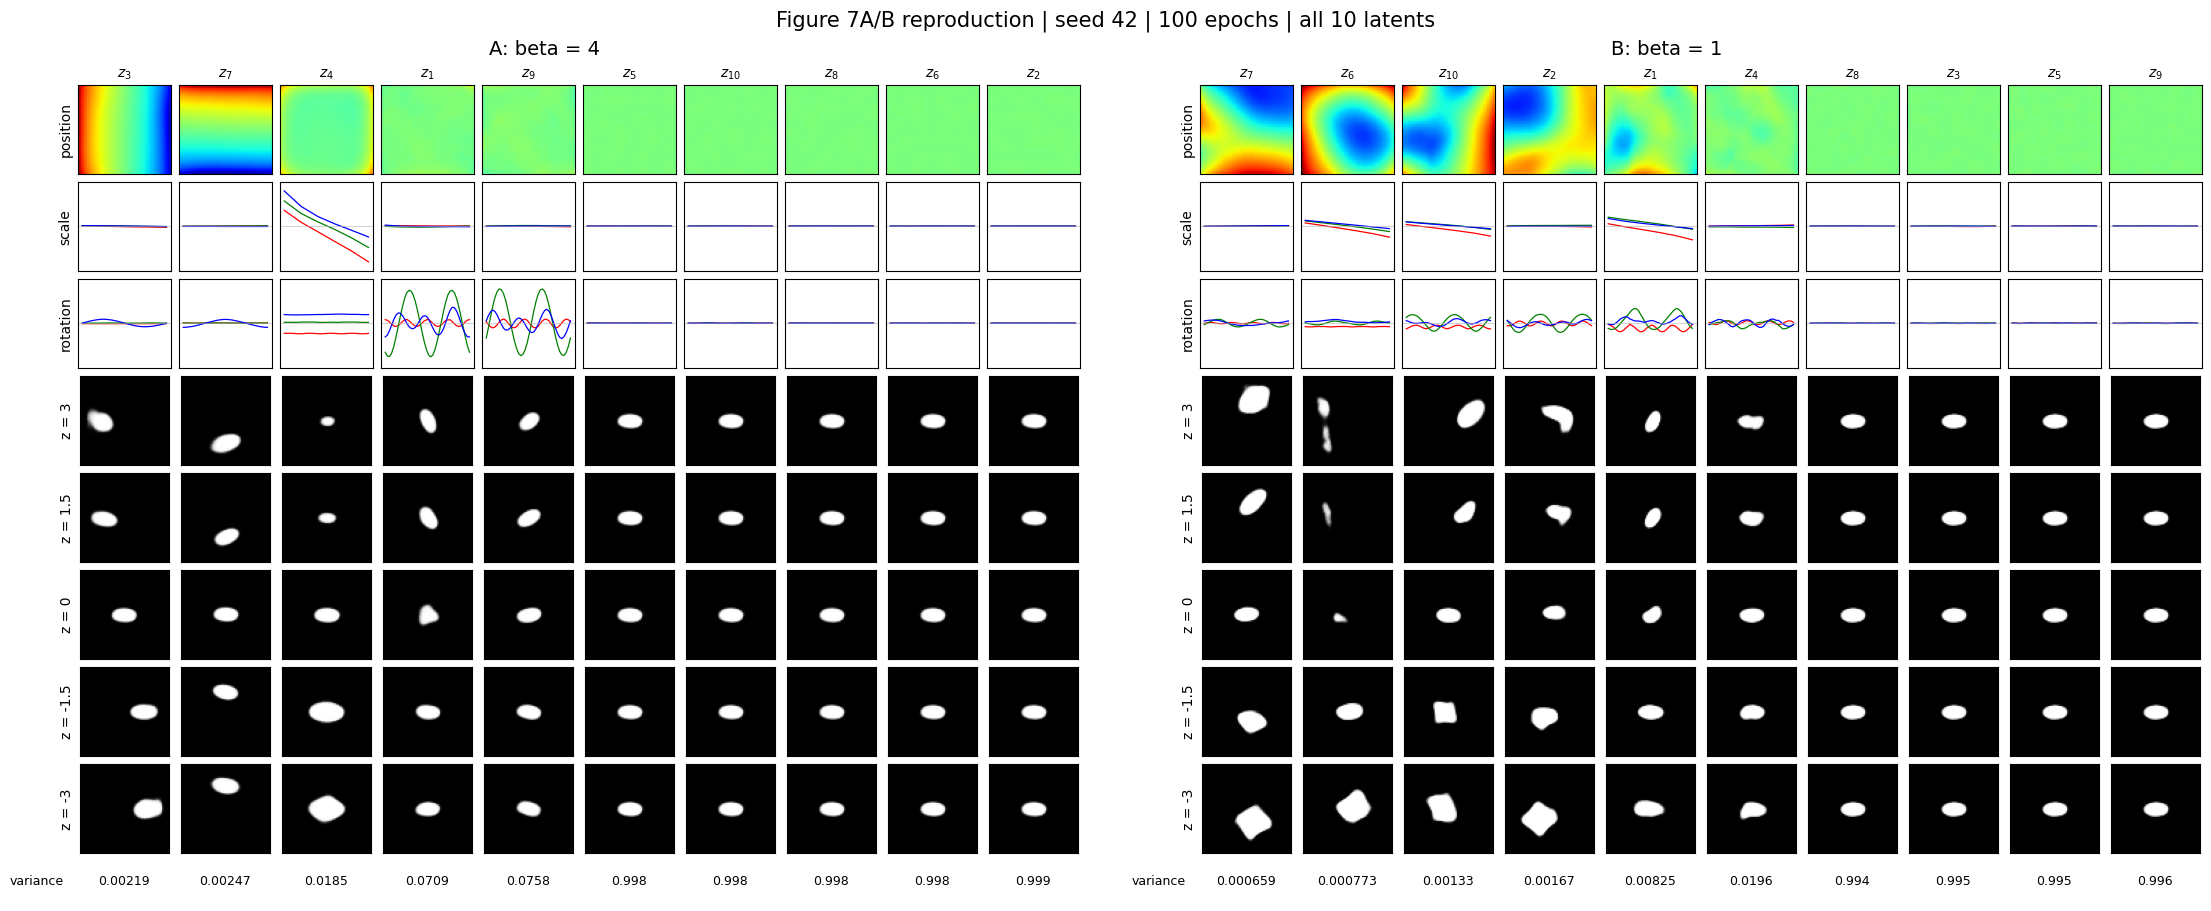

In [6]:
# Shared response scale is derived from both models, not chosen to match the paper.
response_limit = max(float(np.abs(s[k]).max()) for s in summaries.values()
                     for k in ("position", "scale", "rotation"))
response_limit = response_limit or 1.0
colors = ("red", "green", "blue")
fig = plt.figure(figsize=(22, 9), layout="constrained")
panels = fig.subfigures(1, 2, wspace=0.04)
for panel, label, beta in zip(panels, ("A", "B"), BETAS):
    stats = summaries[beta]
    order = np.argsort(stats["variance"], kind="stable")
    axes = panel.subplots(9, LATENT_DIM, gridspec_kw={"height_ratios": [1, 1, 1, 1, 1, 1, 1, 1, 0.45]})
    panel.suptitle(f"{label}: beta = {beta:g}", fontsize=14)
    for column, j in enumerate(order):
        axes[0, column].imshow(stats["position"][:, :, j].T, origin="lower", cmap="jet",
                               vmin=-response_limit, vmax=response_limit, aspect="auto")
        axes[0, column].set_title(f"$z_{{{j+1}}}$", fontsize=10)
        for shape, color in enumerate(colors):
            axes[1, column].plot(SCALE_VALUES, stats["scale"][shape, :, j], color=color, lw=0.9)
            axes[2, column].plot(ROTATION_VALUES, stats["rotation"][shape, :, j], color=color, lw=0.9)
        for row in (1, 2):
            axes[row, column].set_ylim(-response_limit, response_limit)
            axes[row, column].axhline(0, color="0.7", lw=0.4)
        for row, value in enumerate(TRAVERSAL, start=3):
            axes[row, column].imshow(stats["traversal"][j, row-3], cmap="gray", vmin=0, vmax=1)
        axes[8, column].text(0.5, 0.5, f"{stats['variance'][j]:.3g}", ha="center", va="center", fontsize=9)
        axes[8, column].set_axis_off()
        for row in range(8):
            axes[row, column].set_xticks([]); axes[row, column].set_yticks([])
    labels = ["position", "scale", "rotation"] + [f"z = {v:g}" for v in TRAVERSAL]
    for row, label_text in enumerate(labels):
        axes[row, 0].set_ylabel(label_text, fontsize=10)
    axes[8, 0].text(-0.15, 0.5, "variance", transform=axes[8, 0].transAxes,
                    ha="right", va="center", fontsize=9)
fig.suptitle(f"Figure 7A/B reproduction | seed {SEED} | {EPOCHS} epochs | all 10 latents", fontsize=15)
fig.savefig(OUT / "figure7_AB.png", dpi=200)
fig.savefig(OUT / "figure7_AB.pdf")
plt.show()